In [1]:
pip install numpy pandas scikit-learn xgboost lightgbm catboost


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 MB 7.8 MB/s eta 0:00:00


In [13]:
# Check scikit-learn version
import sklearn
print(sklearn.__version__)


1.2.2


In [37]:
data.columns

Index(['ID', 'Geography', 'Primary_Sector', 'Entity_Trade_Name',
       'Annual_Turnover', 'Entity_Status', 'Country_of_Primary_Operation',
       'Coal_Consumption', 'Electricity _Consumption', 'Gas _Consumption',
       'Geographic _Code', 'Region', 'NG_Consumption', 'Petrol_Consumption',
       'SIC _Group', 'Section', 'Sector', 'Structure_Type'],
      dtype='object')

In [39]:
print(data.columns)


Index(['ID', 'Geography', 'Primary_Sector', 'Entity_Trade_Name',
       'Annual_Turnover', 'Entity_Status', 'Country_of_Primary_Operation',
       'Coal_Consumption', 'Electricity _Consumption', 'Gas _Consumption',
       'Geographic _Code', 'Region', 'NG_Consumption', 'Petrol_Consumption',
       'SIC _Group', 'Section', 'Sector', 'Structure_Type'],
      dtype='object')


# Cross validation for each ML model

In [43]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Load the dataset
data = pd.read_excel('/content/New_Dataset_Business.xlsx')

# Define the target column
target_column = 'Electricity _Consumption'

# Explicitly convert target column to numeric for regression, handling potential errors
data[target_column] = pd.to_numeric(data[target_column], errors='coerce')

# Drop rows with missing target values
data.dropna(subset=[target_column], inplace=True)

# Identify categorical and numerical columns, EXCLUDING the target column
categorical_columns = data.select_dtypes(include=['object']).columns.tolist() # Drop removed here
numeric_columns = data.select_dtypes(include=['int64', 'float64']).columns.drop(target_column).tolist()

# Separate preprocessing for categorical and numeric data
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Combine transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_columns),
        ('num', numeric_transformer, numeric_columns)
    ])

# Define models within the pipeline
models = {
    'Linear Regression': Pipeline([('preprocessor', preprocessor),
                                   ('regressor', LinearRegression())]),
    'Decision Tree': Pipeline([('preprocessor', preprocessor),
                               ('regressor', DecisionTreeRegressor())]),
    'Random Forest': Pipeline([('preprocessor', preprocessor),
                               ('regressor', RandomForestRegressor())]),
    'SVR': Pipeline([('preprocessor', preprocessor),
                     ('regressor', SVR())]),
    'XGBoost': Pipeline([('preprocessor', preprocessor),
                         ('regressor', XGBRegressor(objective='reg:squarederror'))]),
    'LightGBM': Pipeline([('preprocessor', preprocessor),
                          ('regressor', LGBMRegressor())]),
    'CatBoost': Pipeline([('preprocessor', preprocessor),
                          ('regressor', CatBoostRegressor(verbose=0))])
}

# K-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Perform cross-validation and print results
for name, model in models.items():
    mse_scores = cross_val_score(model, data[categorical_columns+numeric_columns], data[target_column], scoring='neg_mean_squared_error', cv=kf)
    rmse_scores = np.sqrt(-mse_scores)
    print(f'{name} - Mean RMSE: {np.mean(rmse_scores):.3f}, Std Dev: {np.std(rmse_scores):.3f}')


Linear Regression - Mean RMSE: 17.792, Std Dev: 4.949
Decision Tree - Mean RMSE: 15.769, Std Dev: 6.265
Random Forest - Mean RMSE: 16.984, Std Dev: 12.456
SVR - Mean RMSE: 51.168, Std Dev: 30.452
XGBoost - Mean RMSE: 17.798, Std Dev: 11.736
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000099 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 971
[LightGBM] [Info] Number of data points in the train set: 727, number of used features: 64
[LightGBM] [Info] Start training from score 15.540068
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

<Figure size 1000x800 with 0 Axes>

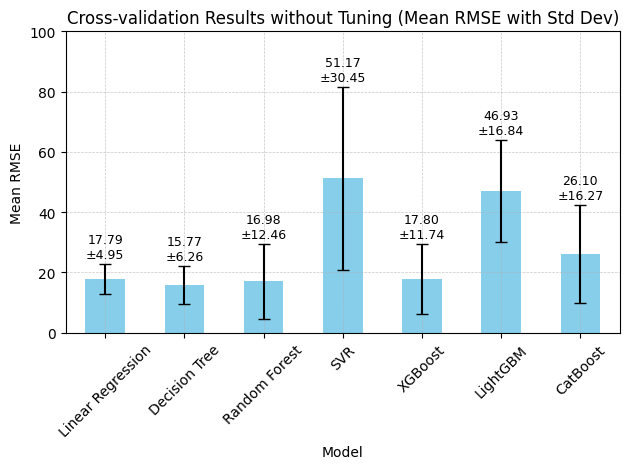

In [34]:
import matplotlib.pyplot as plt
import pandas as pd

# Data preparation
data = {
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'SVR', 'XGBoost', 'LightGBM', 'CatBoost'],
    'Mean RMSE': [17.792, 15.769, 16.984, 51.168, 17.798, 46.930, 26.102],
    'Std Dev': [4.949, 6.265, 12.456, 30.452, 11.736, 16.837, 16.269]
}

df = pd.DataFrame(data)

# Plotting
plt.figure(figsize=(10, 8))  # Increased figure size for better clarity
ax = df.plot.bar(x='Model', y='Mean RMSE', yerr='Std Dev', capsize=4, color='skyblue', legend=False)
plt.xlabel('Model')
plt.ylabel('Mean RMSE')
plt.title('Cross-validation Results without Tuning (Mean RMSE with Std Dev)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
ax.set_ylim(0, 100)  # Increase the y-axis limit to prevent overlapping

# Adding text labels for Mean RMSE and Std Dev on the bars
for idx, row in df.iterrows():
    y_pos = row['Mean RMSE'] + row['Std Dev'] + 2  # Adjust position to be above the error bar
    plt.text(idx, y_pos, f"{row['Mean RMSE']:.2f}\n±{row['Std Dev']:.2f}", ha='center', fontsize=9)

# Display the plot
plt.tight_layout()
plt.show()


# After tuning cross validation

In [48]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Load the dataset
data = pd.read_excel('/content/New_Dataset_Business.xlsx')

# Define the target column
target_column = 'Electricity _Consumption'

# Convert target column to numeric and handle missing values
data[target_column] = pd.to_numeric(data[target_column], errors='coerce')
data.dropna(subset=[target_column], inplace=True)

# Identify feature columns (categorical and numerical)
categorical_columns = data.select_dtypes(include=['object']).columns.tolist()
numeric_columns = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
feature_columns = categorical_columns + numeric_columns

# Preprocessing pipelines for categorical and numerical data
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Combined preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_columns),
        ('num', numeric_transformer, numeric_columns)
    ])


# Define the models and their parameter grids (example)
model_params = {
    'Linear Regression': {
        'model': LinearRegression(),
        'params': {
            'regressor__fit_intercept': [True, False]
        }
    },
    'Decision Tree': {
        'model': DecisionTreeRegressor(),
        'params': {
            'regressor__max_depth': [None, 10, 20],
            'regressor__min_samples_leaf': [1, 2, 4]
        }
    },
    'Random Forest': {
        'model': RandomForestRegressor(),
        'params': {
            'regressor__n_estimators': [10, 50, 100],
            'regressor__max_depth': [None, 10, 20],
            'regressor__min_samples_leaf': [1, 2, 4]
        }
    },
    'SVR': {
        'model': SVR(),
        'params': {
            'regressor__C': [0.1, 1, 10],
            'regressor__kernel': ['linear', 'rbf']
        }
    },
    'XGBoost': {
        'model': XGBRegressor(),
        'params': {
            'regressor__n_estimators': [50, 100, 200],
            'regressor__max_depth': [3, 5, 7]
        }
    },
    'LightGBM': {
        'model': LGBMRegressor(),
        'params': {
            'regressor__n_estimators': [50, 100, 200],
            'regressor__num_leaves': [31, 62, 127]
        }
    },
    'CatBoost': {
        'model': CatBoostRegressor(verbose=0),
        'params': {
            'regressor__iterations': [100, 200],
            'regressor__depth': [4, 6, 10]
        }
    }
}


# K-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

# Perform grid search for each model
for name, mp in model_params.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', mp['model'])
    ])
    gscv = GridSearchCV(pipe, mp['params'], cv=kf, scoring='neg_mean_squared_error', verbose=1, n_jobs=-1)
    gscv.fit(data[feature_columns], data[target_column])

    best_model = gscv.best_estimator_
    best_score = np.sqrt(-gscv.best_score_)
    results.append((name, best_model, gscv.best_params_, best_score))

# Output the results
for name, best_model, best_params, best_score in results:
    print(f"{name}: Best Params = {best_params}, Best RMSE = {best_score:.2f}")


Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Fitting 5 folds for each of 9 candidates, totalling 45 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000322 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1300
[LightGBM] [Info] Number of data points in the train set: 909, number of used features: 69
[LightGBM] [Info] Start training from score 16.145008
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

/usr/local/lib/python3.10/dist-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Linear Regression: Best Params = {'regressor__fit_intercept': True}, Best RMSE = 0.00
Decision Tree: Best Params = {'regressor__max_depth': None, 'regressor__min_samples_leaf': 2}, Best RMSE = 11.13
Random Forest: Best Params = {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1, 'regressor__n_estimators': 100}, Best RMSE = 15.21
SVR: Best Params = {'regressor__C': 0.1, 'regressor__kernel': 'linear'}, Best RMSE = 0.06
XGBoost: Best Params = {'regressor__max_depth': 3, 'regressor__n_estimators': 200}, Best RMSE = 29.39
LightGBM: Best Params = {'regressor__n_estimators': 100, 'regressor__num_leaves': 62}, Best RMSE = 48.14
CatBoost: Best Params = {'regressor__depth': 4, 'regressor__iterations': 200}, Best RMSE = 19.47


In [6]:
pip install --upgrade pandas matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 72.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 84.0 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.0.3
    Uninstalling pandas-2.0.3:
      Successfully uninstalled pandas-2.0.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.7.1
    Uninstalling matplotlib-3.7.1:
      Successfully uninstalled matplotlib-3.7.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu12 24.4.1 requires pandas<2.2.2dev0,>=2.0, but you have pandas 2.2.2 which is incompatible.
google-colab 1.0.0 requires pandas==2.0.3, but you have pandas 2.2.2 which is incompatible.


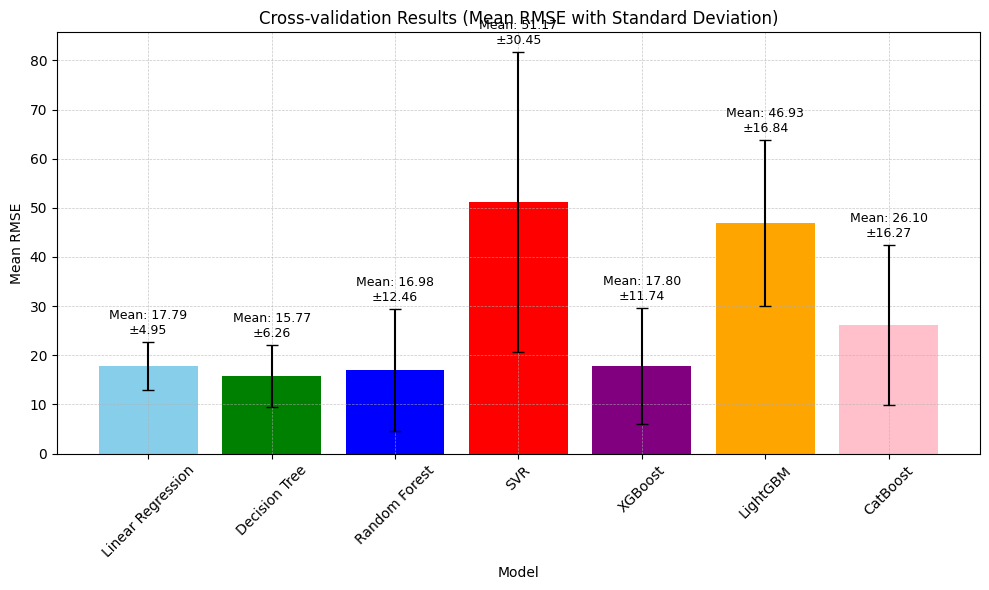

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# Data preparation
data = {
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'SVR', 'XGBoost', 'LightGBM', 'CatBoost'],
    'Mean RMSE': [17.792, 15.769, 16.984, 51.168, 17.798, 46.930, 26.102],
    'Std Dev': [4.949, 6.265, 12.456, 30.452, 11.736, 16.837, 16.269]
}

df = pd.DataFrame(data)

# Colors for the bars, each model gets a unique color
colors = ['skyblue', 'green', 'blue', 'red', 'purple', 'orange', 'pink']

# Plotting
plt.figure(figsize=(10, 6))
bars = plt.bar(df['Model'], df['Mean RMSE'], yerr=df['Std Dev'], color=colors, capsize=4)

# Adding text labels for Mean RMSE and Std Dev on the bars
for bar, mean_rmse, std_dev in zip(bars, df['Mean RMSE'], df['Std Dev']):
    plt.text(bar.get_x() + bar.get_width() / 2, mean_rmse + std_dev + 1,
             f'Mean: {mean_rmse:.2f}\n±{std_dev:.2f}', ha='center', va='bottom', color='black', fontsize=9)

plt.xlabel('Model')
plt.ylabel('Mean RMSE')
plt.title('Cross-validation Results (Mean RMSE with Standard Deviation)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()


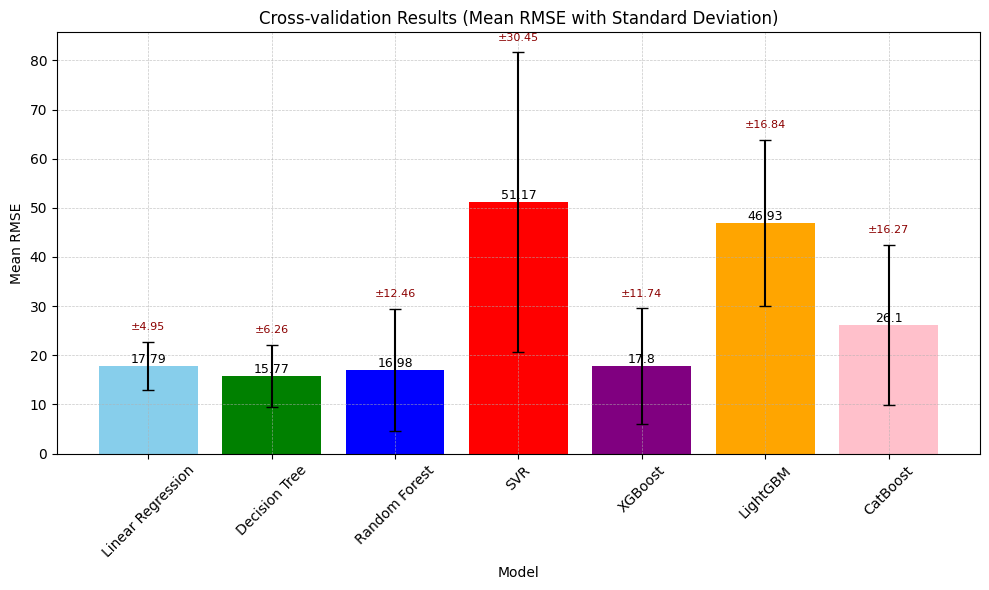

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Data preparation
data = {
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'SVR', 'XGBoost', 'LightGBM', 'CatBoost'],
    'Mean RMSE': [17.792, 15.769, 16.984, 51.168, 17.798, 46.930, 26.102],
    'Std Dev': [4.949, 6.265, 12.456, 30.452, 11.736, 16.837, 16.269]
}

df = pd.DataFrame(data)

# Colors for the bars
colors = ['skyblue', 'green', 'blue', 'red', 'purple', 'orange', 'pink']

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(df['Model'], df['Mean RMSE'], yerr=df['Std Dev'], capsize=4, color=colors)

# Adding text labels above bars
for bar, mean_rmse, std_dev in zip(bars, df['Mean RMSE'], df['Std Dev']):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval, round(mean_rmse, 2), ha='center', va='bottom', fontsize=9, color='black')
    ax.text(bar.get_x() + bar.get_width()/2, yval + std_dev + 2, f'±{round(std_dev, 2)}', ha='center', va='bottom', fontsize=8, color='darkred')

plt.xlabel('Model')
plt.ylabel('Mean RMSE')
plt.title('Cross-validation Results (Mean RMSE with Standard Deviation)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()


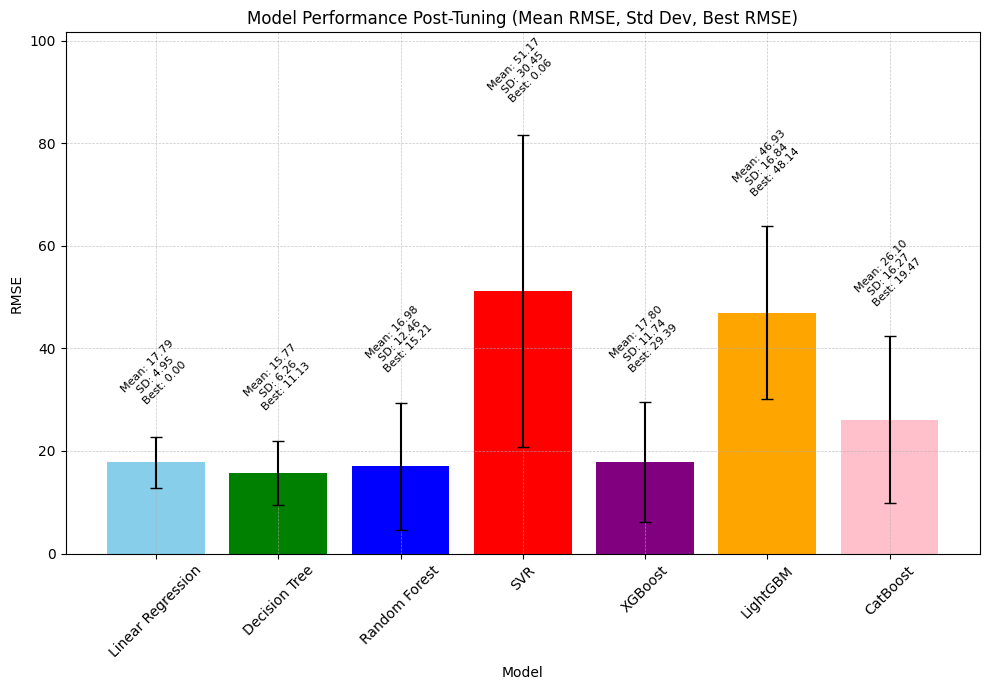

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# Data preparation
data = {
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'SVR', 'XGBoost', 'LightGBM', 'CatBoost'],
    'Mean RMSE': [17.792, 15.769, 16.984, 51.168, 17.798, 46.930, 26.102],
    'Std Dev': [4.949, 6.265, 12.456, 30.452, 11.736, 16.837, 16.269],
    'Best RMSE': [0.00, 11.13, 15.21, 0.06, 29.39, 48.14, 19.47]
}

df = pd.DataFrame(data)

# Colors for the bars
colors = ['skyblue', 'green', 'blue', 'red', 'purple', 'orange', 'pink']

# Plotting
fig, ax = plt.subplots(figsize=(10, 7))  # Increased figure size for better clarity
bars = ax.bar(df['Model'], df['Mean RMSE'], yerr=df['Std Dev'], color=colors, capsize=4, label='Mean RMSE + Std Dev')

# Determine the maximum height to adjust text placement and y-axis limit
max_height = max(df['Mean RMSE'] + df['Std Dev'])
ax.set_ylim(0, max_height + 20)  # Add some space above the tallest bar for text

# Adding text labels for Mean RMSE, Std Dev, and Best RMSE on the bars
for bar, mean_rmse, std_dev, best_rmse in zip(bars, df['Mean RMSE'], df['Std Dev'], df['Best RMSE']):
    y_position = bar.get_height() + std_dev + 5  # Adjust position above the error bar more dynamically
    plt.text(bar.get_x() + bar.get_width() / 2, y_position,
             f'Mean: {mean_rmse:.2f}\nSD: {std_dev:.2f}\nBest: {best_rmse:.2f}',
             ha='center', va='bottom', fontsize=8, color='black', rotation=45)  # Rotate text for better fit

ax.set_xlabel('Model')
ax.set_ylabel('RMSE')
ax.set_title('Model Performance Post-Tuning (Mean RMSE, Std Dev, Best RMSE)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()  # Adjust layout to make room for plot elements
plt.show()
